# Binary Morphology Lab
### OpenCV | Thresholding, Binarization & Morphological Transformations

**Learning objectives**

By the end of this notebook, you will be able to:

- Convert grayscale images into binary masks using global, Otsu, and adaptive thresholding.
- Understand how threshold selection affects foreground/background separation.
- Use structuring elements (kernels) to manipulate binary shapes.
- Apply erosion, dilation, opening, and closing for practical image-cleaning tasks.
- Extract boundaries and small-scale details using morphological gradient, top-hat, and black-hat operations.

> **Notebook scope:** This notebook covers thresholding and the morphological operations introduced up to the supplementary morphology section. It uses different classic OpenCV sample images and generated geometric examples rather than reusing the images from the previous notebook.

## 1. Environment Setup

We use OpenCV for image processing, NumPy for numerical operations, and Matplotlib for visualization.

If the packages are not installed, run the following command in your terminal:

In [ ]:
# If needed, uncomment and run:
# %pip install opencv-python numpy matplotlib requests

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import requests

print("OpenCV version:", cv2.__version__)

OpenCV version: 5.1.0


## 2. Load the Sample Images

We will use two well-known images from the OpenCV sample collection:

- **Sudoku:** useful for studying uneven illumination and adaptive thresholding.
- **Smarties:** useful for observing object/background contrast and binary segmentation.

The images are downloaded once into a local `assets` folder. If you already have the images, place them in that folder and skip the download.

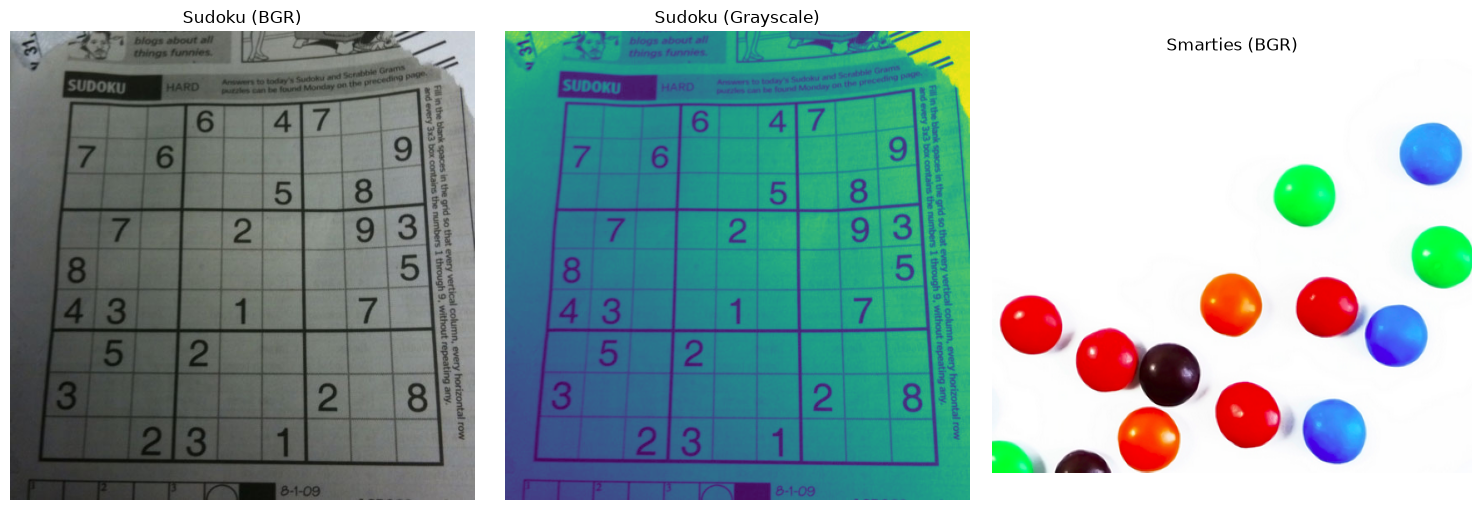

In [2]:
ASSET_DIR = Path("assets")
ASSET_DIR.mkdir(exist_ok=True)

IMAGE_URLS = {
    "sudoku": "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/sudoku.png",
    "smarties": "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/smarties.png",
}

def download_image(name, url):
    path = ASSET_DIR / f"{name}.png"
    if not path.exists():
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        path.write_bytes(response.content)
    return path

for name, url in IMAGE_URLS.items():
    download_image(name, url)

sudoku = cv2.imread(str(ASSET_DIR / "sudoku.png"))
smarties = cv2.imread(str(ASSET_DIR / "smarties.png"))

if sudoku is None or smarties is None:
    raise FileNotFoundError("Could not load the sample images. Check the assets folder.")

sudoku_gray = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)
smarties_gray = cv2.cvtColor(smarties, cv2.COLOR_BGR2GRAY)

def show_images(images, titles, cmap=None, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (image, title) in enumerate(zip(images, titles), 1):
        plt.subplot(1, len(images), i)
        if image.ndim == 3:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        plt.imshow(image, cmap=cmap if image.ndim == 2 else None)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_images(
    [sudoku, sudoku_gray, smarties],
    ["Sudoku (BGR)", "Sudoku (Grayscale)", "Smarties (BGR)"],
    figsize=(15, 5)
)

## 3. Why Binarization?

A grayscale image stores intensity values, typically from **0 (black)** to **255 (white)**. A binary image represents each pixel using only two values:

- `0`: background
- `255`: foreground

Binarization is useful when the goal is to separate an object or region from its background. The quality of this separation strongly affects all later operations, including morphology, connected-component analysis, and contour extraction.

For a threshold value `T`, binary thresholding is defined as:

\[
g(x,y)=
\begin{cases}
255 & \text{if } f(x,y)>T \\
0 & \text{otherwise}
\end{cases}
\]

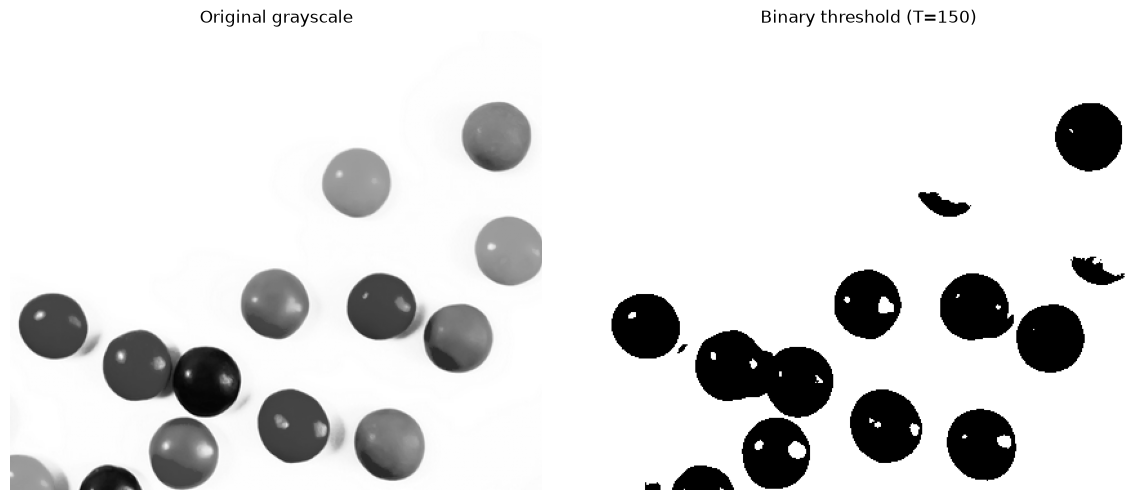

In [3]:
threshold_value = 150

_, binary_smarties = cv2.threshold(
    smarties_gray,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

show_images(
    [smarties_gray, binary_smarties],
    ["Original grayscale", f"Binary threshold (T={threshold_value})"],
    cmap="gray",
    figsize=(12, 5)
)

## 4. Global Thresholding

In global thresholding, one threshold value is applied to every pixel in the image.

### OpenCV syntax

```python
retval, dst = cv2.threshold(src, thresh, maxval, type)
```

| Argument | Meaning |
|---|---|
| `src` | Input grayscale image |
| `thresh` | Threshold value |
| `maxval` | Output value assigned to selected pixels |
| `type` | Thresholding method |
| `retval` | Threshold value used by OpenCV |
| `dst` | Thresholded output image |

### Five common thresholding types

1. `THRESH_BINARY`
2. `THRESH_BINARY_INV`
3. `THRESH_TRUNC`
4. `THRESH_TOZERO`
5. `THRESH_TOZERO_INV`

Only the first two always produce a strictly binary image.

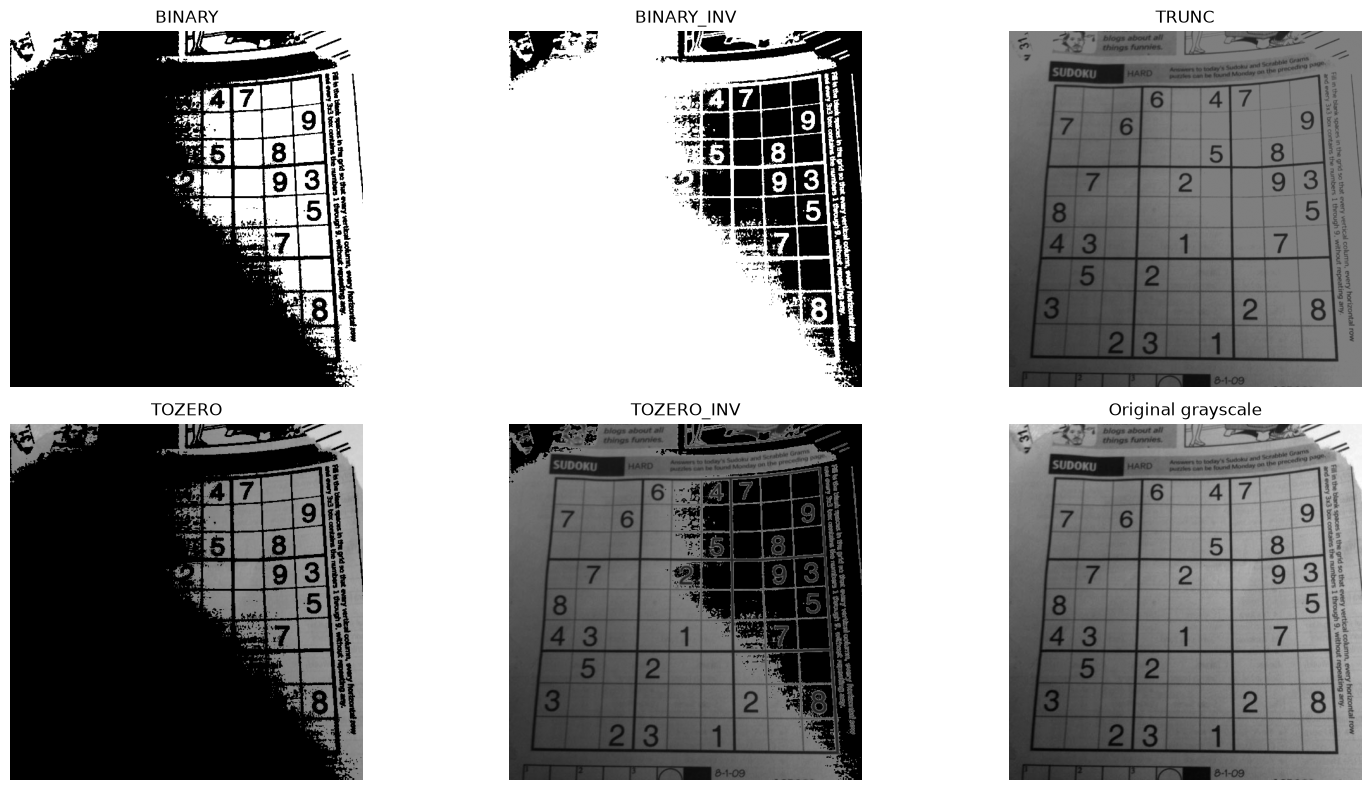

In [4]:
threshold_types = [
    (cv2.THRESH_BINARY, "BINARY"),
    (cv2.THRESH_BINARY_INV, "BINARY_INV"),
    (cv2.THRESH_TRUNC, "TRUNC"),
    (cv2.THRESH_TOZERO, "TOZERO"),
    (cv2.THRESH_TOZERO_INV, "TOZERO_INV"),
]

plt.figure(figsize=(16, 8))
for i, (method, name) in enumerate(threshold_types, 1):
    _, result = cv2.threshold(sudoku_gray, 127, 255, method)
    plt.subplot(2, 3, i)
    plt.imshow(result, cmap="gray", vmin=0, vmax=255)
    plt.title(name)
    plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(sudoku_gray, cmap="gray")
plt.title("Original grayscale")
plt.axis("off")
plt.tight_layout()
plt.show()

### Experiment 1 — How does the threshold value change the result?

A low threshold classifies more pixels as foreground in `THRESH_BINARY`. A high threshold makes the foreground region smaller.

Try several values and compare the resulting masks.

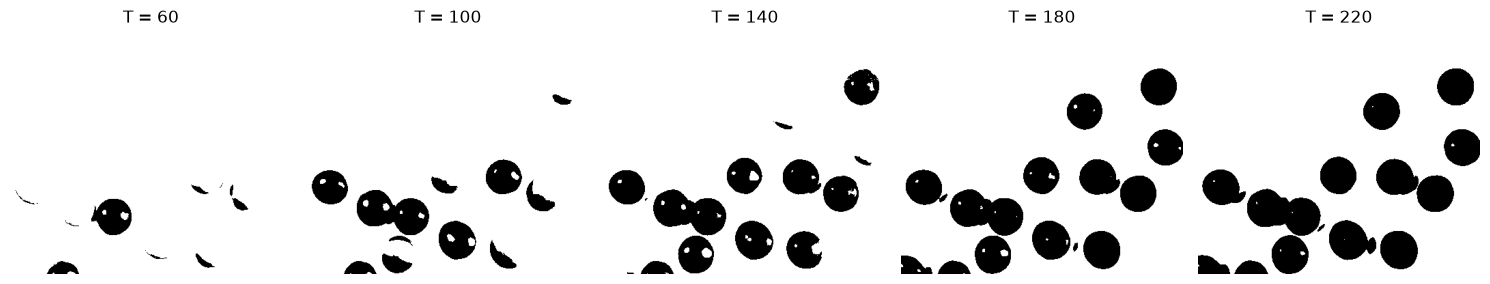

In [5]:
thresholds = [60, 100, 140, 180, 220]

plt.figure(figsize=(15, 5))
for i, t in enumerate(thresholds, 1):
    _, result = cv2.threshold(
        smarties_gray, t, 255, cv2.THRESH_BINARY
    )
    plt.subplot(1, len(thresholds), i)
    plt.imshow(result, cmap="gray")
    plt.title(f"T = {t}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Otsu's Binarization

Choosing a threshold manually is not always convenient. **Otsu's method** automatically selects a global threshold by analyzing the image histogram.

The central idea is to divide the pixels into two classes and select the threshold that maximizes between-class variance (equivalently, minimizes within-class variance).

\[
\sigma_b^2(T)=\omega_0(T)\omega_1(T)
\left[\mu_0(T)-\mu_1(T)\right]^2
\]

Where:

- \(\omega_0, \omega_1\): proportions of pixels in the two classes.
- \(\mu_0, \mu_1\): mean intensities of the two classes.

The optimal threshold is:

\[
T^*=\arg\max_T \sigma_b^2(T)
\]

Otsu often works well when the histogram has two reasonably separated groups. It is a **global** method, so it may struggle with strong illumination variation.

Otsu threshold: 97.0


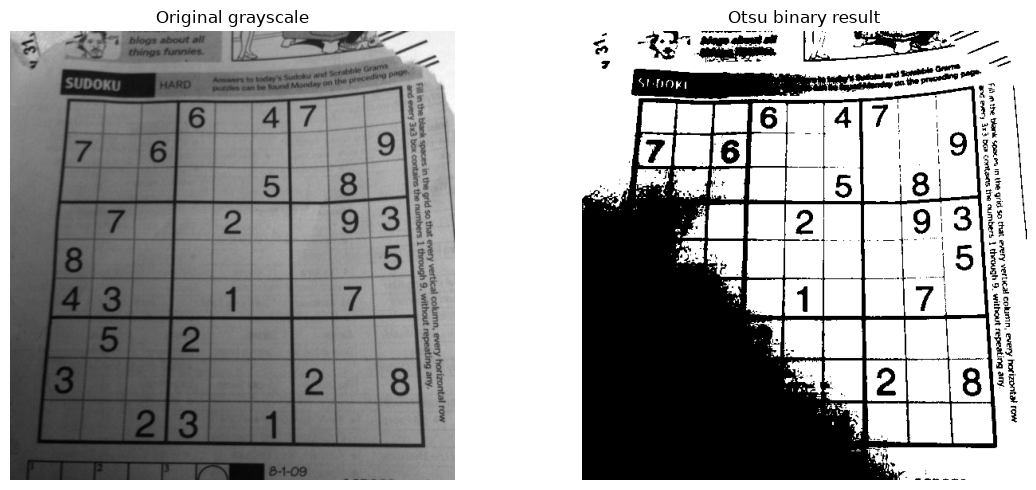

In [6]:
otsu_threshold, otsu_result = cv2.threshold(
    sudoku_gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu threshold:", otsu_threshold)

show_images(
    [sudoku_gray, otsu_result],
    ["Original grayscale", "Otsu binary result"],
    cmap="gray",
    figsize=(12, 5)
)

### 5.1 Otsu after Gaussian blurring

Noise can create small intensity variations and make thresholding less stable. A Gaussian filter can reduce high-frequency noise before applying Otsu.

\[
I_{smooth}=G_{\sigma}*I
\]

Here, `*` denotes convolution.

Otsu threshold after blur: 97.0


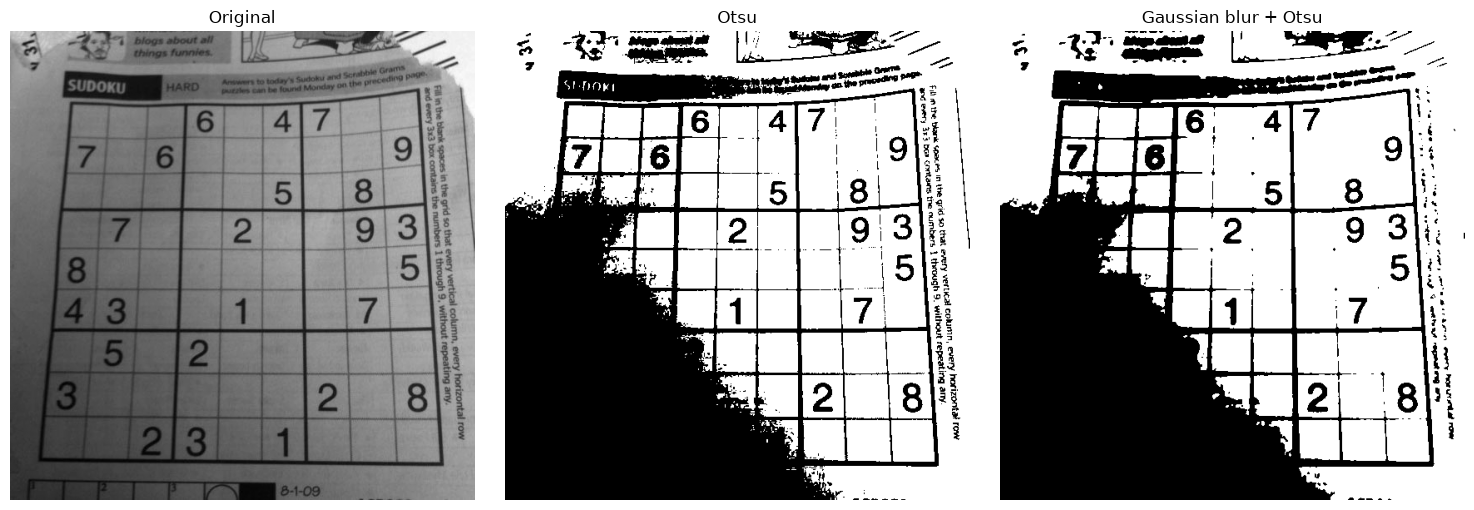

In [7]:
sudoku_blur = cv2.GaussianBlur(sudoku_gray, (5, 5), 0)

otsu_blur_threshold, otsu_blur = cv2.threshold(
    sudoku_blur,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu threshold after blur:", otsu_blur_threshold)

show_images(
    [sudoku_gray, otsu_result, otsu_blur],
    ["Original", "Otsu", "Gaussian blur + Otsu"],
    cmap="gray",
    figsize=(15, 5)
)

## 6. Adaptive Thresholding

A single global threshold is not ideal when different parts of an image have different illumination levels. Adaptive thresholding calculates a local threshold for each pixel using a neighborhood around it.

Two methods are available:

- `ADAPTIVE_THRESH_MEAN_C`: local arithmetic mean minus a constant `C`.
- `ADAPTIVE_THRESH_GAUSSIAN_C`: Gaussian-weighted local mean minus `C`.

\[
T(x,y)=\operatorname{LocalMean}(x,y)-C
\]

`blockSize` specifies the neighborhood width and height. It must be an odd integer greater than 1.

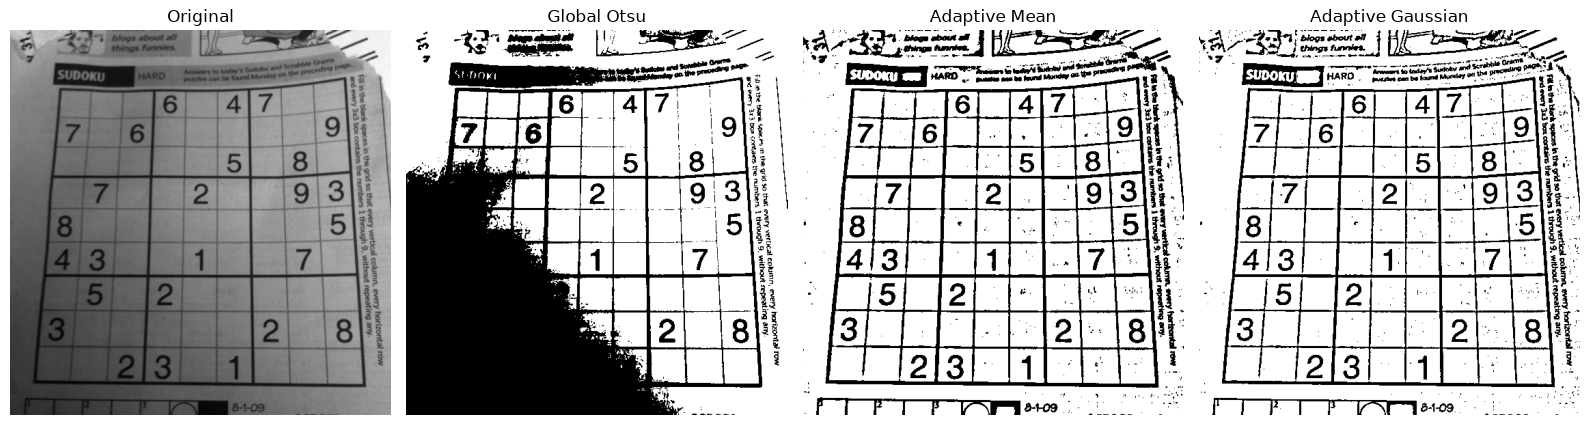

In [8]:
adaptive_mean = cv2.adaptiveThreshold(
    sudoku_gray,
    255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    21,
    5
)

adaptive_gaussian = cv2.adaptiveThreshold(
    sudoku_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    21,
    5
)

show_images(
    [sudoku_gray, otsu_result, adaptive_mean, adaptive_gaussian],
    ["Original", "Global Otsu", "Adaptive Mean", "Adaptive Gaussian"],
    cmap="gray",
    figsize=(16, 5)
)

### Experiment 2 — Tune `blockSize` and `C`

- Increasing `blockSize` makes the local neighborhood larger.
- Increasing `C` subtracts a larger value from the local estimate.
- Very small neighborhoods may be sensitive to noise.
- Very large neighborhoods may behave more like global thresholding.

Try different parameter combinations on the Sudoku image.

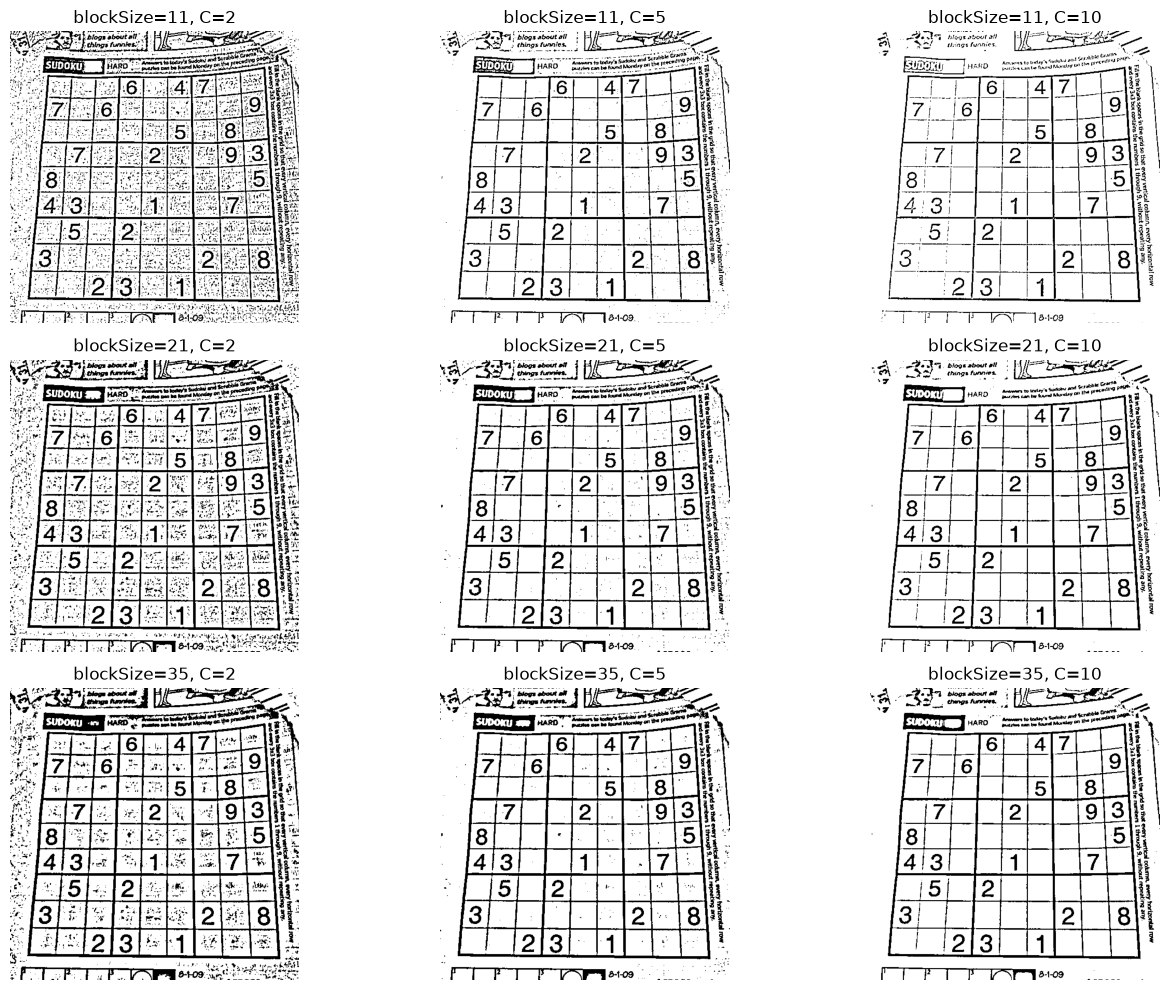

In [9]:
block_sizes = [11, 21, 35]
C_values = [2, 5, 10]

plt.figure(figsize=(14, 10))
plot_index = 1

for block_size in block_sizes:
    for C in C_values:
        result = cv2.adaptiveThreshold(
            sudoku_gray,
            255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY,
            block_size,
            C
        )
        plt.subplot(len(block_sizes), len(C_values), plot_index)
        plt.imshow(result, cmap="gray")
        plt.title(f"blockSize={block_size}, C={C}")
        plt.axis("off")
        plot_index += 1

plt.tight_layout()
plt.show()

# Part II — Morphological Transformations

Morphological operations process image structures according to their shape. They are especially useful after binarization to remove small noise, connect broken regions, fill small gaps, and extract boundaries.

## 7. Structuring Elements (Kernels)

A structuring element is a small matrix that defines the neighborhood used by a morphological operation.

OpenCV can create rectangular, cross-shaped, and elliptical structuring elements.

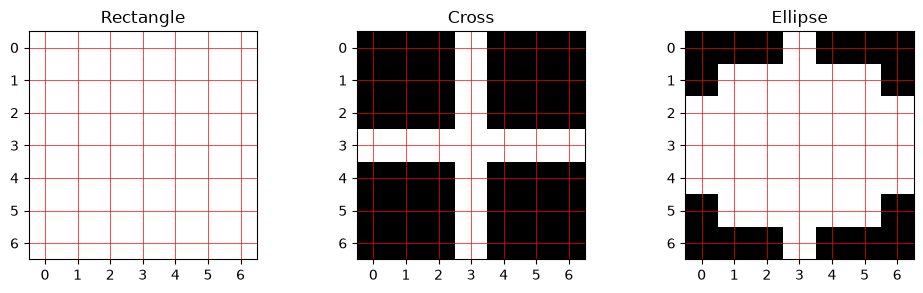

In [10]:
kernel_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))
kernel_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (7, 7))
kernel_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, kernel, title in zip(
    axes,
    [kernel_rect, kernel_cross, kernel_ellipse],
    ["Rectangle", "Cross", "Ellipse"]
):
    ax.imshow(kernel, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(kernel.shape[1]))
    ax.set_yticks(range(kernel.shape[0]))
    ax.grid(True, color="red", linewidth=0.5)
plt.tight_layout()
plt.show()

## 8. Create a Controlled Binary Example

Before applying morphology to a real image, it is useful to study its effect on a simple binary mask. The following image contains two rectangular objects, a small isolated noise component, and a narrow gap.

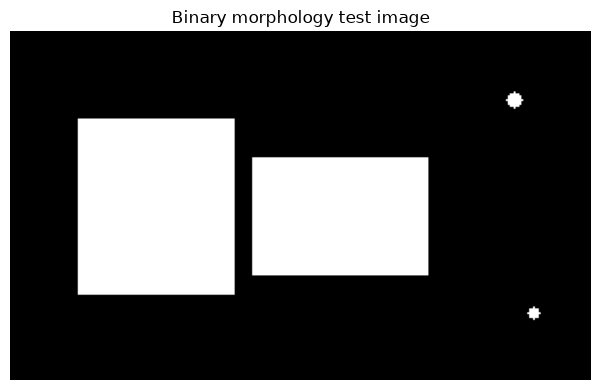

In [11]:
morph_demo = np.zeros((180, 300), dtype=np.uint8)

# Main foreground objects
cv2.rectangle(morph_demo, (35, 45), (115, 135), 255, -1)
cv2.rectangle(morph_demo, (125, 65), (215, 125), 255, -1)

# Small isolated white noise
cv2.circle(morph_demo, (260, 35), 4, 255, -1)
cv2.circle(morph_demo, (270, 145), 3, 255, -1)

show_images([morph_demo], ["Binary morphology test image"], cmap="gray", figsize=(7, 4))

## 9. Erosion

**Erosion** shrinks white foreground regions. For a binary image, a foreground pixel remains white only when the structuring element fits the foreground at that location.

\[
A\ominus B
\]

Typical uses:

- Removing small white noise.
- Separating objects connected by thin bridges.
- Reducing the thickness of foreground structures.

The effect depends on the kernel shape, kernel size, and number of iterations.

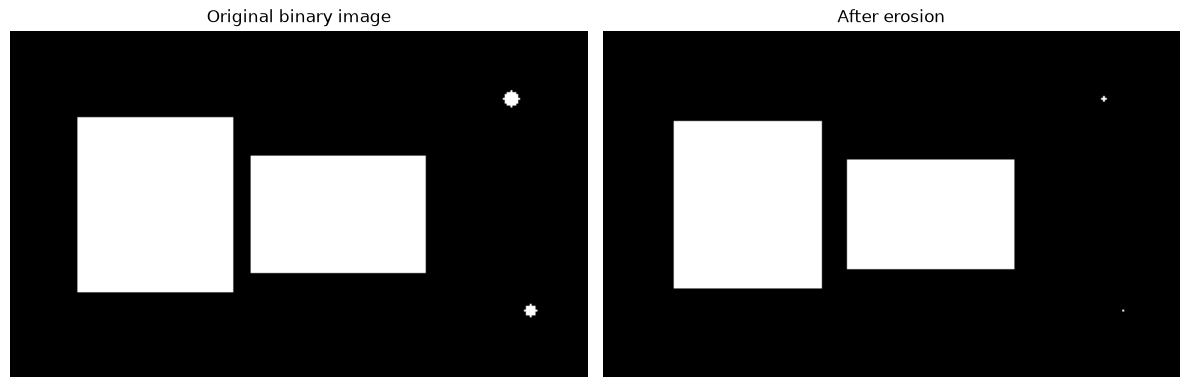

In [12]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

eroded = cv2.erode(
    morph_demo,
    kernel,
    iterations=1
)

show_images(
    [morph_demo, eroded],
    ["Original binary image", "After erosion"],
    cmap="gray",
    figsize=(12, 4)
)

## 10. Dilation

**Dilation** expands white foreground regions. A pixel becomes foreground when the structuring element overlaps the foreground according to the dilation rule.

\[
A\oplus B
\]

Typical uses:

- Connecting nearby foreground regions.
- Filling small gaps between parts of an object.
- Increasing the thickness of lines and shapes.

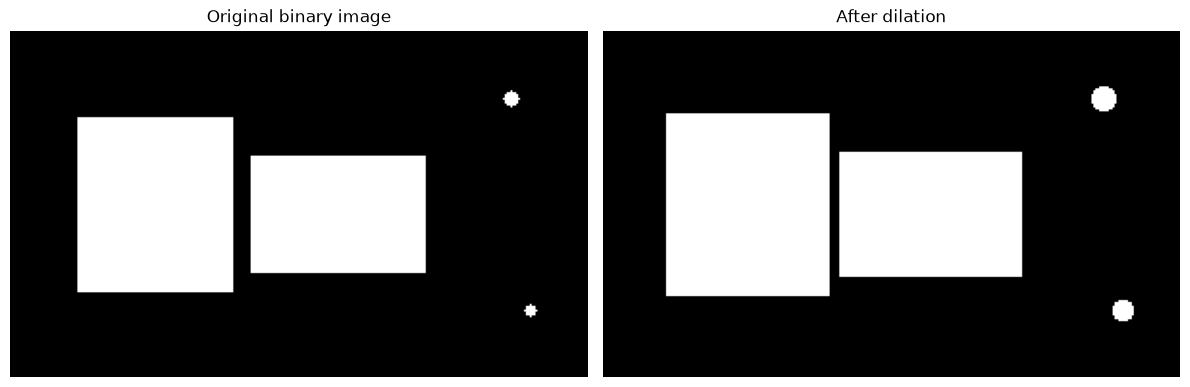

In [13]:
dilated = cv2.dilate(
    morph_demo,
    kernel,
    iterations=1
)

show_images(
    [morph_demo, dilated],
    ["Original binary image", "After dilation"],
    cmap="gray",
    figsize=(12, 4)
)

### Experiment 3 — Kernel size and iterations

A larger kernel or more iterations usually produces a stronger morphological effect. Compare the outcomes below.

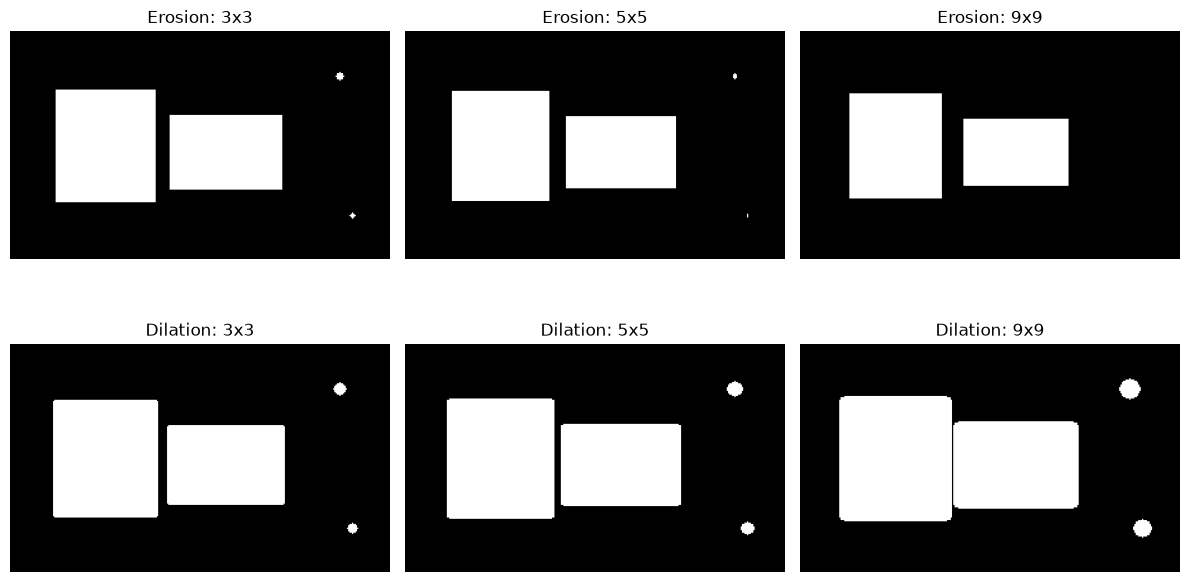

In [14]:
kernel_sizes = [3, 5, 9]

plt.figure(figsize=(12, 7))
for i, size in enumerate(kernel_sizes, 1):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    er = cv2.erode(morph_demo, k, iterations=1)
    di = cv2.dilate(morph_demo, k, iterations=1)

    plt.subplot(2, 3, i)
    plt.imshow(er, cmap="gray")
    plt.title(f"Erosion: {size}x{size}")
    plt.axis("off")

    plt.subplot(2, 3, i + 3)
    plt.imshow(di, cmap="gray")
    plt.title(f"Dilation: {size}x{size}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 11. Opening

**Opening** is erosion followed by dilation, using the same structuring element:

\[
A\circ B=(A\ominus B)\oplus B
\]

Opening is useful for removing small white foreground objects while preserving the larger structures. The dilation step partially restores the size of the remaining objects, but it does not necessarily reconstruct their exact original shape.

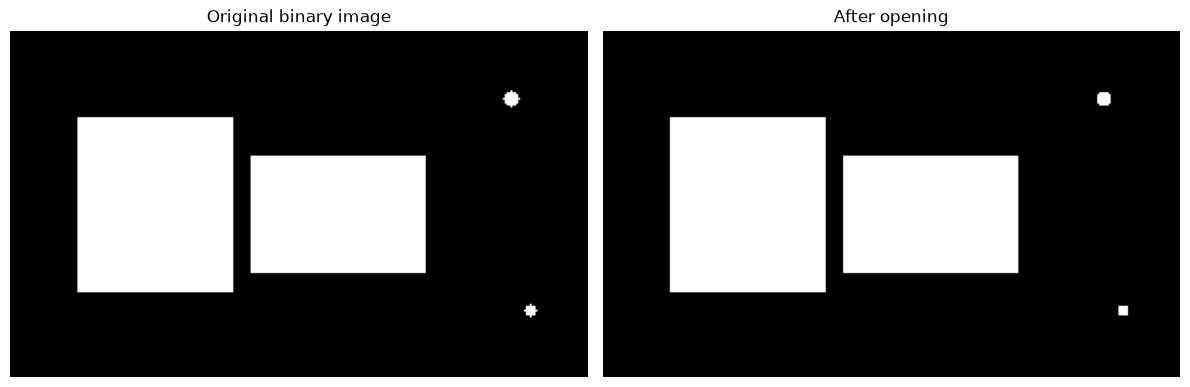

In [15]:
opening = cv2.morphologyEx(
    morph_demo,
    cv2.MORPH_OPEN,
    kernel
)

show_images(
    [morph_demo, opening],
    ["Original binary image", "After opening"],
    cmap="gray",
    figsize=(12, 4)
)

## 12. Closing

**Closing** is dilation followed by erosion:

\[
A\bullet B=(A\oplus B)\ominus B
\]

Closing is useful for filling small dark holes and closing narrow gaps inside foreground objects.

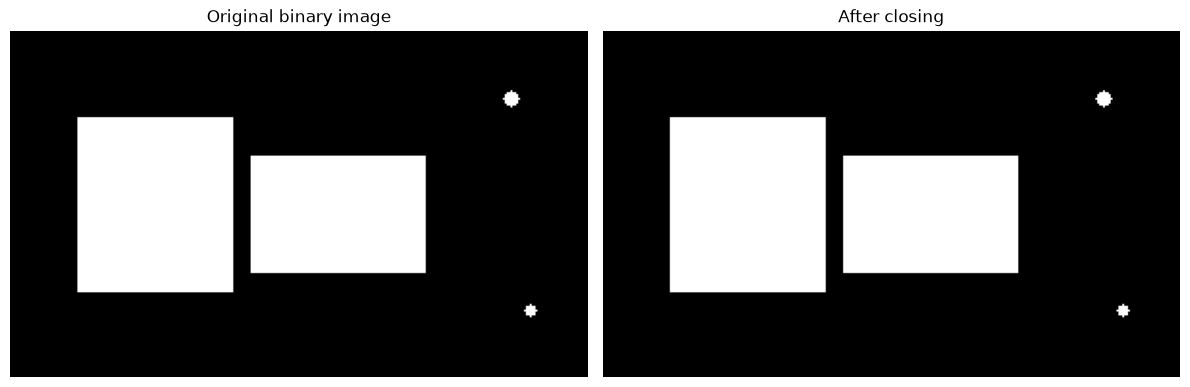

In [16]:
closing = cv2.morphologyEx(
    morph_demo,
    cv2.MORPH_CLOSE,
    kernel
)

show_images(
    [morph_demo, closing],
    ["Original binary image", "After closing"],
    cmap="gray",
    figsize=(12, 4)
)

### Opening vs. Closing

| Operation | Order | Main purpose |
|---|---|---|
| Opening | Erosion → Dilation | Remove small white objects/noise |
| Closing | Dilation → Erosion | Fill small black holes and gaps |

The order matters. Opening and closing are not interchangeable.

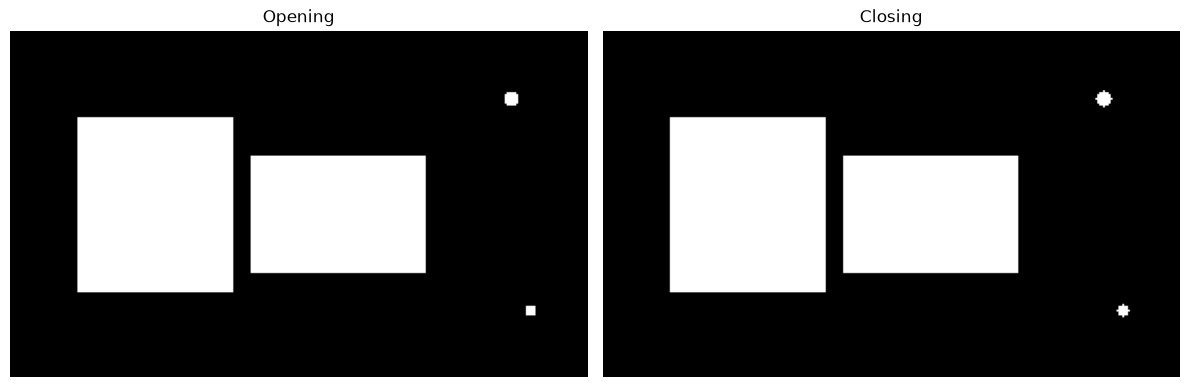

In [17]:
operations = [
    (cv2.MORPH_OPEN, "Opening"),
    (cv2.MORPH_CLOSE, "Closing"),
]

plt.figure(figsize=(12, 4))
for i, (operation, title) in enumerate(operations, 1):
    result = cv2.morphologyEx(morph_demo, operation, kernel)
    plt.subplot(1, 2, i)
    plt.imshow(result, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 13. Morphological Gradient

The morphological gradient highlights object boundaries. It is computed as the difference between dilation and erosion:

\[
Gradient(A)= (A\oplus B)-(A\ominus B)
\]

It produces a boundary-like representation of the foreground objects.

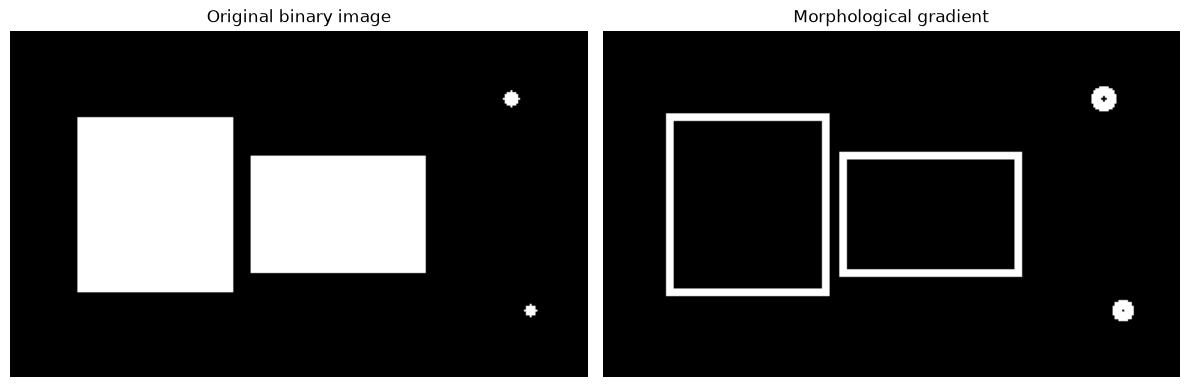

In [18]:
gradient = cv2.morphologyEx(
    morph_demo,
    cv2.MORPH_GRADIENT,
    kernel
)

show_images(
    [morph_demo, gradient],
    ["Original binary image", "Morphological gradient"],
    cmap="gray",
    figsize=(12, 4)
)

## 14. Top Hat

The **Top Hat** transform is the difference between the original image and its opening:

\[
TopHat(A)=A-(A\circ B)
\]

It emphasizes small bright structures that are removed by opening. It can be useful for highlighting bright details on a relatively uneven background.

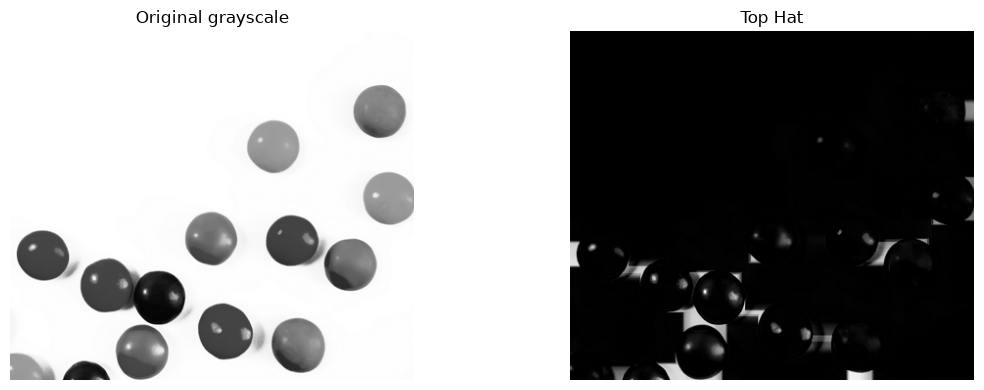

In [19]:
# Top-hat is often informative on grayscale images.
smarties_tophat = cv2.morphologyEx(
    smarties_gray,
    cv2.MORPH_TOPHAT,
    cv2.getStructuringElement(cv2.MORPH_RECT, (21, 21))
)

show_images(
    [smarties_gray, smarties_tophat],
    ["Original grayscale", "Top Hat"],
    cmap="gray",
    figsize=(12, 4)
)

## 15. Black Hat

The **Black Hat** transform is the difference between the closing and the original image:

\[
BlackHat(A)=(A\bullet B)-A
\]

It emphasizes small dark structures or details that are filled by closing.

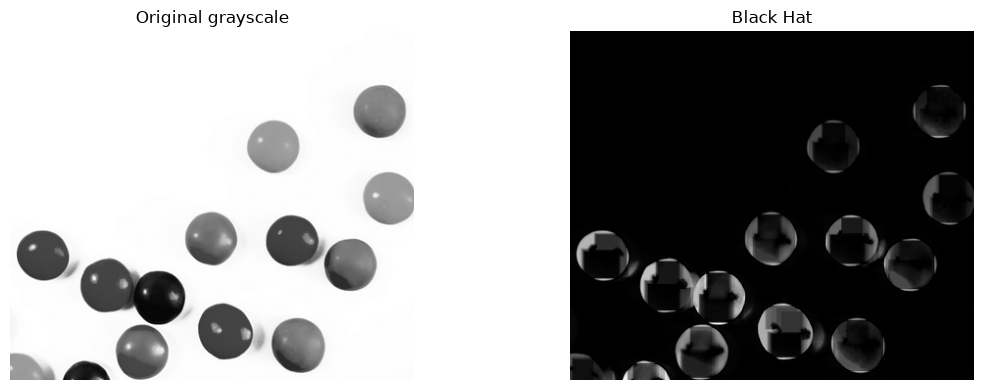

In [20]:
smarties_blackhat = cv2.morphologyEx(
    smarties_gray,
    cv2.MORPH_BLACKHAT,
    cv2.getStructuringElement(cv2.MORPH_RECT, (21, 21))
)

show_images(
    [smarties_gray, smarties_blackhat],
    ["Original grayscale", "Black Hat"],
    cmap="gray",
    figsize=(12, 4)
)

## 16. Practical Example — Cleaning a Thresholded Document

We can combine thresholding and morphology in a small preprocessing pipeline. The goal is to obtain a cleaner binary representation before later tasks such as connected-component analysis or OCR.

This is not a complete OCR system: it only demonstrates image preprocessing.

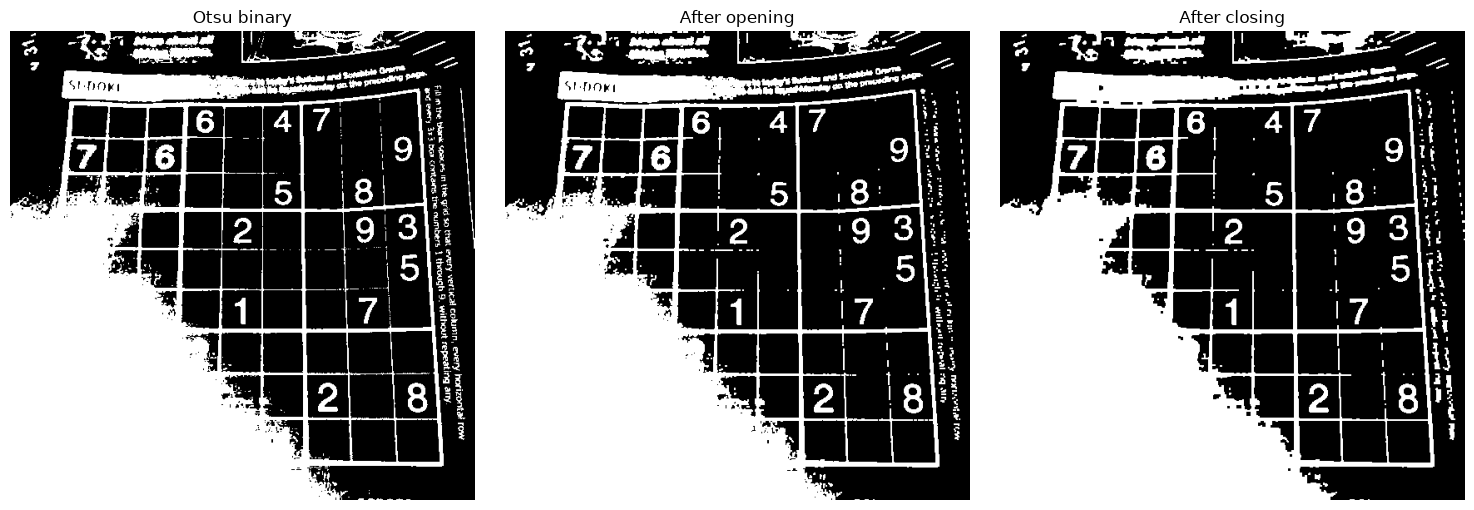

In [21]:
document_gray = sudoku_gray.copy()

# Convert dark text/lines into white foreground
_, document_binary = cv2.threshold(
    document_gray,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove tiny foreground noise
noise_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (2, 2)
)

document_clean = cv2.morphologyEx(
    document_binary,
    cv2.MORPH_OPEN,
    noise_kernel
)

# Close small breaks in foreground strokes
stroke_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (3, 3)
)

document_closed = cv2.morphologyEx(
    document_clean,
    cv2.MORPH_CLOSE,
    stroke_kernel
)

show_images(
    [document_binary, document_clean, document_closed],
    ["Otsu binary", "After opening", "After closing"],
    cmap="gray",
    figsize=(15, 5)
)

## 17. Quick Reference

| Operation | OpenCV function / flag | Main effect |
|---|---|---|
| Global threshold | `cv2.threshold` | Separates pixels using one threshold |
| Otsu | `cv2.THRESH_OTSU` | Automatically selects a global threshold |
| Adaptive threshold | `cv2.adaptiveThreshold` | Uses local thresholds |
| Erosion | `cv2.erode` | Shrinks foreground |
| Dilation | `cv2.dilate` | Expands foreground |
| Opening | `cv2.MORPH_OPEN` | Removes small bright foreground noise |
| Closing | `cv2.MORPH_CLOSE` | Fills small dark gaps/holes |
| Gradient | `cv2.MORPH_GRADIENT` | Highlights boundaries |
| Top Hat | `cv2.MORPH_TOPHAT` | Extracts small bright details |
| Black Hat | `cv2.MORPH_BLACKHAT` | Extracts small dark details |

## 18. Exercises

Try to solve these tasks before checking external examples:

1. Apply global thresholding to `smarties_gray` using at least four threshold values. Explain which value gives the most useful foreground/background separation.
2. Compare Otsu thresholding with adaptive Gaussian thresholding on `sudoku_gray`. Why do their results differ?
3. Create a binary image containing several small white dots and one large object. Use opening to remove the dots while preserving the large object.
4. Create a binary image with a large white object containing small black holes. Use closing to reduce those holes.
5. Apply morphological gradient to a binary image and explain why the output resembles object boundaries.
6. Apply Top Hat and Black Hat to a grayscale image. Identify which local structures each operation emphasizes.

### Key takeaways

- Thresholding converts intensity information into foreground/background masks.
- Otsu is a global automatic thresholding method; adaptive thresholding is local.
- Erosion and dilation are the basic morphological operations.
- Opening and closing combine erosion and dilation in different orders.
- Gradient, Top Hat, and Black Hat reveal different structural details.

**Next topic:** Connected Components and Contour Analysis.